In [756]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model

In [757]:
df = pd.read_csv('Housing.csv')  # Load dataset
df.head(5)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


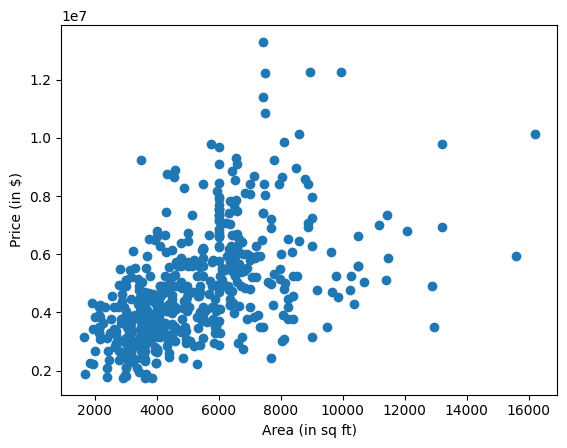

In [758]:
%matplotlib inline
plt.xlabel('Area (in sq ft)')
plt.ylabel('Price (in $)')
plt.scatter(df.area, df.price)

In [759]:
df.groupby('airconditioning')['price'].mean()

airconditioning
no     4.191940e+06
yes    6.013221e+06
Name: price, dtype: float64

In [760]:
df.groupby('stories')['price'].mean()

stories
1    4.170659e+06
2    4.764074e+06
3    5.685436e+06
4    7.208450e+06
Name: price, dtype: float64

In [761]:
df['airconditioning'] = df['airconditioning'].replace({'yes': 1, 'no': 0})

df['hotwaterheating'] = df['hotwaterheating'].replace({'yes': 1, 'no': 0})

df['furnishingstatus'] = df['furnishingstatus'].replace({
    'unfurnished': 0,
    'semi-furnished': 0.5,
    'furnished': 1
})


In [762]:
df.head(5)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,0,1,2,yes,1
1,12250000,8960,4,4,4,yes,no,no,0,1,3,no,1
2,12250000,9960,3,2,2,yes,no,yes,0,0,2,yes,0.5
3,12215000,7500,4,2,2,yes,no,yes,0,1,3,yes,1
4,11410000,7420,4,1,2,yes,yes,yes,0,1,2,no,1


In [763]:
df[['price','area','bedrooms','bathrooms','stories','parking','airconditioning','hotwaterheating','furnishingstatus']].corr()


,price,area,bedrooms,bathrooms,stories,parking,airconditioning,hotwaterheating,furnishingstatus
price,1.000000,0.535997,0.366494,0.517545,0.420712,0.384394,0.452954,0.093073,0.304721
area,0.535997,1.000000,0.151858,0.193820,0.083996,0.352980,0.222393,-0.009229,0.171445
bedrooms,0.366494,0.151858,1.000000,0.373930,0.408564,0.139270,0.160603,0.046049,0.123244
bathrooms,0.517545,0.193820,0.373930,1.000000,0.326165,0.177496,0.186915,0.067159,0.143559
stories,0.420712,0.083996,0.408564,0.326165,1.000000,0.045547,0.293602,0.018847,0.104672
parking,0.384394,0.352980,0.139270,0.177496,0.045547,1.000000,0.159173,0.067864,0.177539
airconditioning,0.452954,0.222393,0.160603,0.186915,0.293602,0.159173,1.000000,-0.130023,0.150477
hotwaterheating,0.093073,-0.009229,0.046049,0.067159,0.018847,0.067864,-0.130023,1.000000,0.031628
furnishingstatus,0.304721,0.171445,0.123244,0.143559,0.104672,0.177539,0.150477,0.031628,1.000000


In [764]:
X = df[['area','bedrooms','bathrooms','stories','parking','airconditioning','furnishingstatus']]
y = df['price']

In [765]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=110,      # exact test size
    random_state=42
)
print(len(X_train), len(X_test))

435 110


In [766]:
reg = linear_model.LinearRegression()
reg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [767]:
y_pred = reg.predict(X_test)

In [768]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)
print("R² score:", r2)

R² score: 0.6003261992864313


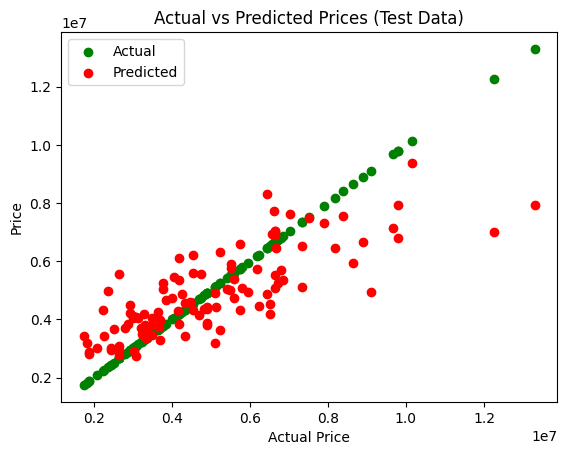

In [769]:
plt.figure()

# Green dots → actual prices
plt.scatter(y_test, y_test, color="green", label="Actual")

# Red dots → predicted prices
plt.scatter(y_test, y_pred, color="red", label="Predicted")

plt.xlabel("Actual Price")
plt.ylabel("Price")
plt.title("Actual vs Predicted Prices (Test Data)")
plt.legend()

plt.show()


In [770]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)
print("MAE:", mae)

MAE: 1063833.490636667


In [771]:
new_house = pd.DataFrame({
    'area': [3300],
    'bedrooms': [3],
    'bathrooms': [2],
    'stories': [2],
    'parking': [1],
    'airconditioning': [1],
    'furnishingstatus': [0.5]
})

reg.predict(new_house)

array([5766878.08190876])